
🧩 MedSSL-3D v0.6 — Mode B: Segmentation (ResidualDecoder3D)

🧪 ENVIRONMENT REPORT
Python      : 3.10.20
PyTorch     : 2.7.1+cu118
MONAI       : 1.4.0
NumPy       : 1.26.4
CUDA avail. : True
GPU         : NVIDIA GeForce RTX 3050 6GB Laptop GPU
GPU memory  : 6.0 GB
Device used : cuda
Run mode    : segmentation
🔒 Seed set to 42

📂 DATA_ROOT : C:/Users/ILIA/Desktop/MedSSL_v0/MICCAI_BraTS2020_TrainingData
📂 MODALITY  : flair
📂 Seg checkpoints -> C:\Users\ILIA\Desktop\MedSSL_Results\checkpoints\segmentation
📂 Seg logs        -> C:\Users\ILIA\Desktop\MedSSL_Results\logs\segmentation

🔍 DATA SANITY CHECK (Mode B — Segmentation)
✅ Directory exists: C:/Users/ILIA/Desktop/MedSSL_v0/MICCAI_BraTS2020_TrainingData
✅ Found 369 'flair' file(s)
⚠️ 1 image file(s) had no matching segmentation mask and were skipped.
✅ Matched 368 (image, mask) pair(s)
📄 First pair:
   image: BraTS20_Training_001_flair.nii
   mask : BraTS20_Training_001_seg.nii
📦 Volume shape: (1, 128, 128, 64) | Mask shape: (1, 128, 128

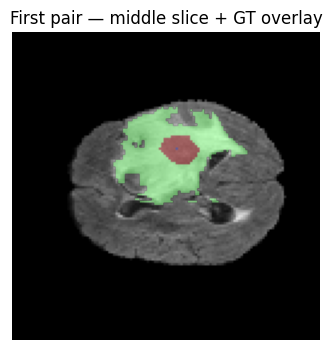

✅ Middle slice + ground-truth overlay displayed above.

✅ SEGMENTATION SANITY CHECK PASSED.


📊 Train pairs: 294 | Val pairs: 74
Encoder path: C:\Users\ILIA\Desktop\MedSSL_Results\checkpoints\encoder.pth
Exists? True
Checkpoint dir: C:\Users\ILIA\Desktop\MedSSL_Results\checkpoints
Files: ['best_model.pth', 'checkpoint_epoch_1.pth', 'checkpoint_epoch_10.pth', 'checkpoint_epoch_11.pth', 'checkpoint_epoch_12.pth', 'checkpoint_epoch_13.pth', 'checkpoint_epoch_14.pth', 'checkpoint_epoch_15.pth', 'checkpoint_epoch_16.pth', 'checkpoint_epoch_17.pth', 'checkpoint_epoch_18.pth', 'checkpoint_epoch_19.pth', 'checkpoint_epoch_2.pth', 'checkpoint_epoch_20.pth', 'checkpoint_epoch_3.pth', 'checkpoint_epoch_4.pth', 'checkpoint_epoch_5.pth', 'checkpoint_epoch_6.pth', 'checkpoint_epoch_7.pth', 'checkpoint_epoch_8.pth', 'checkpoint_epoch_9.pth', 'config.json', 'encoder.pth', 'segmentation']
✅ Loaded pretrained SSL encoder from C:\Users\ILIA\Desktop\MedSSL_Results\checkpoints\encoder.pth

----------------

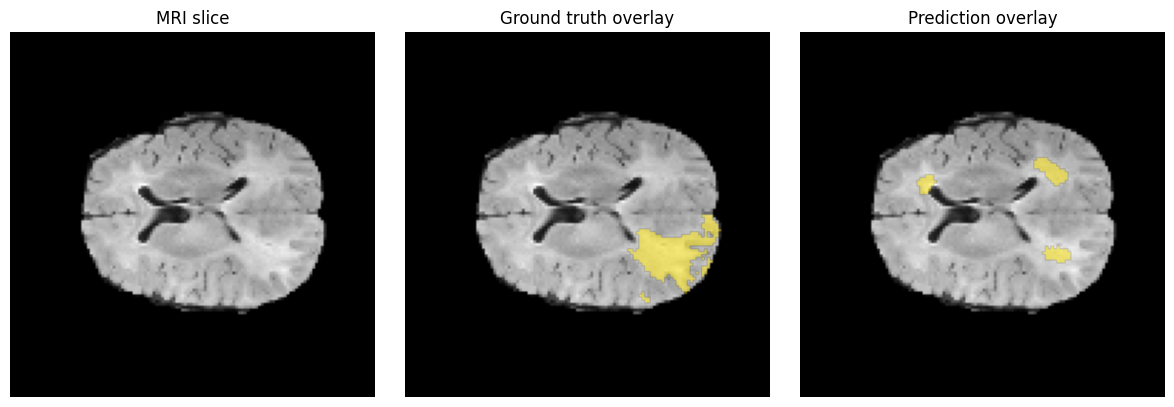

📊 Val Dice: 0.3230 | Val IoU: 0.2177
💾 Segmentation history saved to C:\Users\ILIA\Desktop\MedSSL_Results\logs\segmentation/segmentation_history.csv


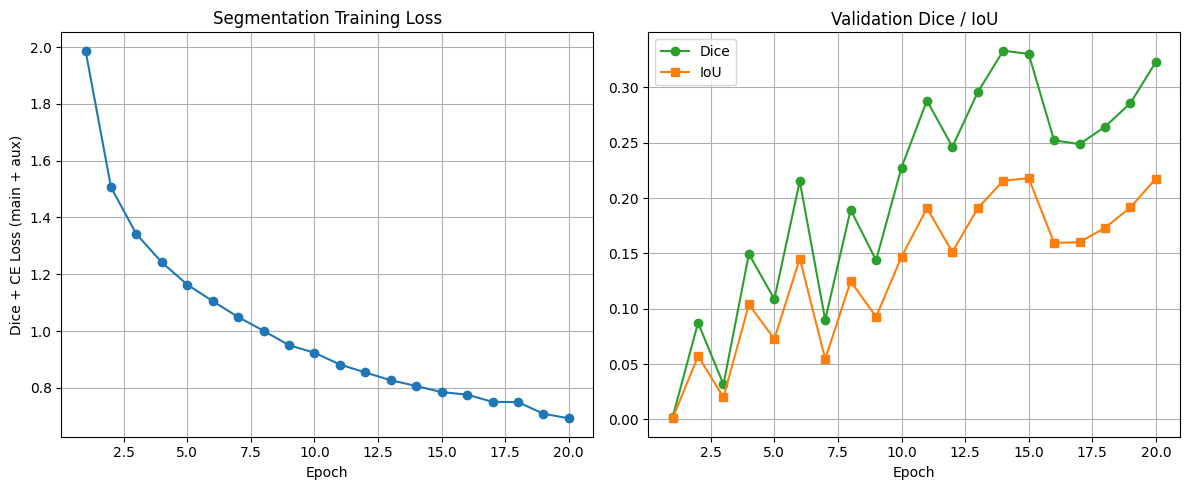


🎉 v0.6 Mode B RUN COMPLETE
💾 Checkpoints -> C:\Users\ILIA\Desktop\MedSSL_Results\checkpoints\segmentation
💾 Logs        -> C:\Users\ILIA\Desktop\MedSSL_Results\logs\segmentation
📌 SimCLR pipeline (Mode A) is untouched — set Config.MODE='simclr' to confirm.


In [1]:
# ==============================================================================
# MedSSL-3D v0.6
# Self-Supervised 3D Medical Representation Learning (SimCLR) + a U-Net-style
# residual segmentation decoder with deep supervision, built directly on top
# of the verified v0.5 pipeline.
#
# Single Google Colab / Jupyter cell — single continuous run.
#
# WHAT'S NEW IN v0.6 (vs v0.5) — DECODER ONLY, per the project roadmap:
#   - ResNet3D.forward() gains a second optional argument, `return_feature_maps`
#     (plural). Called with no arguments (as SimCLR3D does), or with only the
#     old `return_feature_map` (singular) argument, it is BYTE-FOR-BYTE
#     IDENTICAL to v0.5/v0.4 — same ops, same tensors, same return values.
#     Only when `return_feature_maps=True` does it additionally return the
#     pre-pool feature maps from layer1, layer2 and layer3 (not just layer4).
#     No layer was added, removed, resized, or renamed.
#   - SegmentationHead3D (v0.5's shallow, skip-free decoder) is REPLACED by
#     ResidualDecoder3D: a lightweight 3D U-Net-style decoder with classical
#     concatenation skip connections from layer1/2/3, residual decoder
#     blocks, and two deep-supervision auxiliary heads (after Decoder Stage 1
#     and Decoder Stage 3). Only the main output is used at inference time.
#   - Everything else — SimCLR pretraining (Mode A), the segmentation
#     dataset, transforms, label remapping, Dice+CE loss, optimizer,
#     evaluation metrics (Dice/IoU), checkpoint format, logging, and
#     visualization — is UNCHANGED from v0.5.
#
# ONLY LINE YOU SHOULD NEED TO EDIT: Config.DATA_ROOT, below.
#
# Recommended first run: set MODE = 'simclr' once to confirm it behaves
# exactly like v0.4/v0.5 (it will produce the same checkpoints/encoder.pth).
# Then switch MODE = 'segmentation' to exercise the new v0.6 decoder — it
# will automatically pick up that encoder.pth if present, unmodified.
# ==============================================================================

# ------------------------------------------------------------------------------
# 1. Install dependencies
#    (This '!' line is Jupyter/Colab notebook-cell syntax. If you ever run this
#    file as a plain .py script instead of a notebook cell, remove this line
#    and install the packages beforehand with a normal `pip install` command.)
# ------------------------------------------------------------------------------
!pip install -q torch torchvision monai nibabel numpy tqdm matplotlib

# ------------------------------------------------------------------------------
# 2. Imports
# ------------------------------------------------------------------------------
import os
import glob
import json
import csv
import random
import logging
import platform
from typing import Tuple, List, Optional, Union

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader

import monai
from monai.transforms import (
    Compose, LoadImage, EnsureChannelFirst, Resize, NormalizeIntensity,
    RandFlip, RandRotate90, RandGaussianNoise, RandScaleIntensity, RandShiftIntensity,
)

import matplotlib.pyplot as plt
from tqdm import tqdm

# ------------------------------------------------------------------------------
# 3. Logging
# ------------------------------------------------------------------------------
logging.basicConfig(level=logging.INFO, format='%(message)s')
logger = logging.getLogger('MedSSL-3D')


def log_section(title: str) -> None:
    logger.info("\n" + "=" * 80)
    logger.info(title)
    logger.info("=" * 80)


# ------------------------------------------------------------------------------
# 4. Config
# ------------------------------------------------------------------------------
class Config:
    SEED = 42
    DEVICE = 'cuda'

    # ---- Shared by both modes ----
    IMG_SIZE = (128, 128, 64)     # (H, W, D)
    NUM_WORKERS = 0                # keep 0 — safest choice on Colab

    # >>> THE ONLY LINE YOU SHOULD NEED TO EDIT <<<
    DATA_ROOT = 'C:/Users/ILIA/Desktop/MedSSL_v0/MICCAI_BraTS2020_TrainingData'
    MODALITY = 'flair'            # 't1', 't1ce', 't2', or 'flair'

    # ---- Mode switch ----
    MODE = 'segmentation'          # 'simclr' (Mode A, = v0.4/v0.5 unchanged) or 'segmentation' (Mode B)

    # ---- Mode A: SimCLR pretraining (identical defaults to v0.4/v0.5) ----
    BATCH_SIZE = 8
    PROJECTION_DIM = 128
    TEMPERATURE = 0.5
    LR = 1e-4
    NUM_EPOCHS = 20

    # ---- Output directories ----
    DESKTOP_BASE = os.path.join(os.path.expanduser("~"), "Desktop", "MedSSL_Results")
    CHECKPOINT_DIR = os.path.join(DESKTOP_BASE, 'checkpoints')
    LOG_DIR = os.path.join(DESKTOP_BASE, 'logs')
    SEG_CHECKPOINT_DIR = os.path.join(DESKTOP_BASE, 'checkpoints', 'segmentation')
    SEG_LOG_DIR = os.path.join(DESKTOP_BASE, 'logs', 'segmentation')

    # ---- Mode B: Segmentation (dataset/loss/metrics unchanged from v0.5) ----
    NUM_SEG_CLASSES = 4            # background, NCR/NET, edema, enhancing (BraTS label 4 -> 3)
    BATCH_SIZE_SEG = 2              # 3D volumes are memory-heavy; lower this further if you hit OOM
    LR_SEG = 1e-4
    NUM_EPOCHS_SEG = 20
    VAL_FRACTION = 0.2
    USE_PRETRAINED_ENCODER = True
    PRETRAINED_ENCODER_PATH = os.path.join(CHECKPOINT_DIR, 'encoder.pth')   # produced by Mode A

    # ---- Mode B, v0.6 only: deep-supervision auxiliary loss weight ----
    # Applied to each of the two auxiliary heads in ResidualDecoder3D.
    # Main loss keeps weight 1.0, exactly as v0.5's single-output loss did.
    AUX_LOSS_WEIGHT = 0.3

    @classmethod
    def setup_dirs(cls) -> None:
        os.makedirs(cls.CHECKPOINT_DIR, exist_ok=True)
        os.makedirs(cls.LOG_DIR, exist_ok=True)
        os.makedirs(cls.SEG_CHECKPOINT_DIR, exist_ok=True)
        os.makedirs(cls.SEG_LOG_DIR, exist_ok=True)

    @classmethod
    def to_dict(cls) -> dict:
        return {
            k: (list(v) if isinstance(v, tuple) else v)
            for k, v in vars(cls).items()
            if not k.startswith('_') and not callable(v) and not isinstance(v, classmethod)
        }


# ------------------------------------------------------------------------------
# 5. Environment report — helps diagnose Colab / library-version drift
# ------------------------------------------------------------------------------
def print_environment_report() -> None:
    log_section("🧪 ENVIRONMENT REPORT")
    logger.info(f"Python      : {platform.python_version()}")
    logger.info(f"PyTorch     : {torch.__version__}")
    logger.info(f"MONAI       : {monai.__version__}")
    logger.info(f"NumPy       : {np.__version__}")
    logger.info(f"CUDA avail. : {torch.cuda.is_available()}")
    if torch.cuda.is_available():
        logger.info(f"GPU         : {torch.cuda.get_device_name(0)}")
        total_mem = torch.cuda.get_device_properties(0).total_memory / (1024 ** 3)
        logger.info(f"GPU memory  : {total_mem:.1f} GB")
    logger.info(f"Device used : {Config.DEVICE}")
    logger.info(f"Run mode    : {Config.MODE}")


# ------------------------------------------------------------------------------
# 6. Seed
# ------------------------------------------------------------------------------
def set_seed(seed: int = Config.SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    logger.info(f"🔒 Seed set to {seed}")


# ------------------------------------------------------------------------------
# 7. Base loading transforms (deterministic — no randomness) — UNCHANGED
# ------------------------------------------------------------------------------
def build_base_transform(img_size: Tuple[int, int, int]) -> Compose:
    """For MRI volumes: trilinear resize preserves intensity gradients."""
    return Compose([
        LoadImage(image_only=True),
        EnsureChannelFirst(),
        Resize(spatial_size=img_size, mode='trilinear'),
    ])


def build_mask_transform(img_size: Tuple[int, int, int]) -> Compose:
    """For segmentation masks: nearest-neighbor resize keeps integer class labels intact."""
    return Compose([
        LoadImage(image_only=True),
        EnsureChannelFirst(),
        Resize(spatial_size=img_size, mode='nearest'),
    ])


# ------------------------------------------------------------------------------
# 8. Mode A — Data Sanity Check (unchanged from v0.4/v0.5; stops on failure)
# ------------------------------------------------------------------------------
def run_data_sanity_check(data_root: str, modality: str,
                           img_size: Tuple[int, int, int]) -> List[str]:
    """
    Pre-flight check for the SimCLR (Mode A) data pipeline:
      - directory exists
      - files for the chosen modality are found
      - first file loads, with sane shape / dtype / min / max
      - no NaN / Inf
      - a middle slice is displayed for visual confirmation
    Raises SystemExit with a clear message on any failure.
    """
    log_section("🔍 DATA SANITY CHECK (Mode A — SimCLR)")

    if not os.path.isdir(data_root):
        raise SystemExit(
            f"❌ DATA_ROOT does not exist: '{data_root}'\n"
            f"   -> Update Config.DATA_ROOT to the folder where you downloaded BraTS."
        )
    logger.info(f"✅ Directory exists: {data_root}")

    pattern = os.path.join(data_root, '**', f'*{modality}*.nii*')
    image_paths = sorted(glob.glob(pattern, recursive=True))

    if len(image_paths) == 0:
        raise SystemExit(
            f"❌ No files matching modality '{modality}' were found under '{data_root}'.\n"
            f"   Checked pattern: {pattern}\n"
            f"   -> Confirm the dataset was extracted correctly and the modality name "
            f"matches your filenames (e.g. 't1', 't1ce', 't2', 'flair')."
        )
    logger.info(f"✅ Found {len(image_paths)} file(s) for modality '{modality}'")
    logger.info(f"📄 First file: {os.path.basename(image_paths[0])}")

    base_transform = build_base_transform(img_size)
    try:
        volume = base_transform(image_paths[0])
    except Exception as e:
        raise SystemExit(f"❌ Failed to load/transform the first file: {e}")

    if not torch.is_tensor(volume):
        volume = torch.as_tensor(np.asarray(volume))

    logger.info(f"📦 Shape : {tuple(volume.shape)}")
    logger.info(f"🔢 Dtype : {volume.dtype}")

    expected_shape = (1, *img_size)
    if tuple(volume.shape) != expected_shape:
        raise SystemExit(
            f"❌ Unexpected volume shape: got {tuple(volume.shape)}, expected {expected_shape}."
        )

    vol_f = volume.float()
    logger.info(f"📉 Min value : {vol_f.min().item():.4f}")
    logger.info(f"📈 Max value : {vol_f.max().item():.4f}")

    if torch.isnan(vol_f).any():
        raise SystemExit(f"❌ NaN values detected in '{image_paths[0]}'.")
    if torch.isinf(vol_f).any():
        raise SystemExit(f"❌ Inf values detected in '{image_paths[0]}'.")
    logger.info("✅ No NaN / Inf detected")

    try:
        mid_slice = vol_f[0, :, :, vol_f.shape[-1] // 2]
        plt.figure(figsize=(4, 4))
        plt.imshow(mid_slice.numpy(), cmap='gray')
        plt.title(f"Middle slice — {os.path.basename(image_paths[0])}")
        plt.axis('off')
        plt.show()
        logger.info("✅ Middle slice displayed above.")
    except Exception as e:
        logger.warning(f"⚠️ Could not display middle slice (non-fatal): {e}")

    logger.info("\n✅ SANITY CHECK PASSED — proceeding.\n")
    return image_paths


# ------------------------------------------------------------------------------
# 9. Mode A — Contrastive dataset (unchanged from v0.4/v0.5)
# ------------------------------------------------------------------------------
def build_augmentation_pipeline() -> Compose:
    """
    Builds a FRESH list of transform instances every time it's called.
    Two separate calls never share the same transform objects, so view1
    and view2 augmentations are genuinely independent.
    """
    return Compose([
        RandFlip(spatial_axis=0, prob=0.3),
        RandFlip(spatial_axis=1, prob=0.3),
        RandFlip(spatial_axis=2, prob=0.3),
        RandRotate90(prob=0.3, max_k=1),
        RandGaussianNoise(prob=0.2, mean=0.0, std=0.1),
        RandScaleIntensity(factors=0.1, prob=0.3),
        RandShiftIntensity(offsets=0.1, prob=0.3),
        NormalizeIntensity(nonzero=True, channel_wise=True),
    ])


class BraTSDataset(Dataset):
    """Two independently-augmented views of each volume, for SimCLR (Mode A)."""
    def __init__(self, image_paths: List[str],
                 img_size: Tuple[int, int, int] = Config.IMG_SIZE,
                 is_train: bool = True):
        self.image_paths = image_paths
        self.img_size = img_size
        self.is_train = is_train
        self.base_transform = build_base_transform(img_size)

        if is_train:
            self.augment1 = build_augmentation_pipeline()
            self.augment2 = build_augmentation_pipeline()
        else:
            self.augment1 = Compose([NormalizeIntensity(nonzero=True, channel_wise=True)])
            self.augment2 = Compose([NormalizeIntensity(nonzero=True, channel_wise=True)])

    def __len__(self) -> int:
        return len(self.image_paths)

    def __getitem__(self, idx: int):
        volume = self.base_transform(self.image_paths[idx])
        if not torch.is_tensor(volume):
            volume = torch.as_tensor(np.asarray(volume))
        volume = volume.float()

        if torch.isnan(volume).any() or torch.isinf(volume).any():
            logger.warning(
                f"⚠️ NaN/Inf found in {self.image_paths[idx]} — sanitizing with "
                f"nan_to_num so one bad sample doesn't crash the whole epoch."
            )
            volume = torch.nan_to_num(volume, nan=0.0, posinf=0.0, neginf=0.0)

        view1 = self.augment1(volume.clone())
        view2 = self.augment2(volume.clone())

        if not torch.is_tensor(view1):
            view1 = torch.as_tensor(np.asarray(view1))
        if not torch.is_tensor(view2):
            view2 = torch.as_tensor(np.asarray(view2))

        return view1.float(), view2.float()


# ------------------------------------------------------------------------------
# 10. Model core — encoder UNCHANGED architecture from v0.3/v0.4/v0.5.
#     ResNet3D.forward gains a SECOND optional argument (`return_feature_maps`,
#     plural) on top of v0.5's `return_feature_map` (singular). Every layer
#     definition below is identical to the verified v0.3 pipeline; no weight,
#     shape, or computation changes. A v0.5 encoder.pth loads here unmodified.
# ------------------------------------------------------------------------------
class BasicBlock3D(nn.Module):
    def __init__(self, in_channels, out_channels, stride=1):
        super().__init__()
        self.conv1 = nn.Conv3d(in_channels, out_channels, 3, stride, 1, bias=False)
        self.bn1 = nn.BatchNorm3d(out_channels)
        self.conv2 = nn.Conv3d(out_channels, out_channels, 3, 1, 1, bias=False)
        self.bn2 = nn.BatchNorm3d(out_channels)
        self.shortcut = nn.Identity()
        if in_channels != out_channels or stride != 1:
            self.shortcut = nn.Sequential(
                nn.Conv3d(in_channels, out_channels, 1, stride, bias=False),
                nn.BatchNorm3d(out_channels)
            )

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        return F.relu(out)


class ResNet3D(nn.Module):
    def __init__(self, in_channels=1):
        super().__init__()
        self.in_channels = 64
        self.conv1 = nn.Conv3d(in_channels, 64, 7, 2, 3, bias=False)
        self.bn1 = nn.BatchNorm3d(64)
        self.pool = nn.MaxPool3d(3, 2, 1)
        self.layer1 = self._make_layer(64, 2, 1)
        self.layer2 = self._make_layer(128, 2, 2)
        self.layer3 = self._make_layer(256, 2, 2)
        self.layer4 = self._make_layer(512, 2, 2)
        self.avgpool = nn.AdaptiveAvgPool3d((1, 1, 1))

        # Channel counts of layer1..layer4 outputs — used by the v0.6 decoder
        # to size its skip-connection concatenations. Purely descriptive;
        # does not affect the encoder's own computation in any way.
        self.stage_channels = (64, 128, 256, 512)

    def _make_layer(self, out_channels, blocks, stride):
        layers = [BasicBlock3D(self.in_channels, out_channels, stride)]
        self.in_channels = out_channels
        for _ in range(1, blocks):
            layers.append(BasicBlock3D(out_channels, out_channels))
        return nn.Sequential(*layers)

    def forward(self, x, return_feature_map: bool = False, return_feature_maps: bool = False):
        """
        Default call `encoder(x)` (used by SimCLR3D, Mode A): returns just the
        (B, 512) global vector — byte-for-byte identical to v0.4/v0.5.

        `encoder(x, return_feature_map=True)` (v0.5's Mode B call): returns
        (layer4_feature_map, global_vector) — identical to v0.5.

        `encoder(x, return_feature_maps=True)` (NEW in v0.6, used only by the
        v0.6 segmentation path): additionally returns the layer1/2/3 feature
        maps needed for U-Net-style skip connections. The forward computation
        itself — every conv/bn/relu op — is exactly the same regardless of
        which of these flags is set; only which intermediate tensors get
        returned changes.
        """
        x = self.pool(F.relu(self.bn1(self.conv1(x))))
        l1 = self.layer1(x)
        l2 = self.layer2(l1)
        l3 = self.layer3(l2)
        l4 = self.layer4(l3)                               # (B, 512, d, h, w) — spatial
        pooled = self.avgpool(l4)
        global_vector = torch.flatten(pooled, 1)            # (B, 512) — exactly v0.4/v0.5's output

        if return_feature_maps:
            return l1, l2, l3, l4, global_vector
        if return_feature_map:
            return l4, global_vector
        return global_vector                                # default path: identical to v0.4/v0.5


def resnet18_3d(in_channels=1):
    return ResNet3D(in_channels)


class ProjectionHead(nn.Module):
    def __init__(self, input_dim=512, hidden_dim=512, output_dim=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.net(x)


class SimCLR3D(nn.Module):
    """Unchanged from v0.4/v0.5 — calls self.encoder(x) with no extra argument,
    so it only ever sees the (B, 512) global vector, exactly as before."""
    def __init__(self, encoder, projection_dim=128):
        super().__init__()
        self.encoder = encoder
        self.projection = ProjectionHead(input_dim=512, output_dim=projection_dim)

    def forward(self, x1, x2, return_features=False):
        h1 = self.encoder(x1)
        h2 = self.encoder(x2)
        z1 = self.projection(h1)
        z2 = self.projection(h2)
        if return_features:
            return z1, z2, h1, h2
        return z1, z2

    def get_encoder(self):
        return self.encoder


def nt_xent_loss(z1, z2, temperature=Config.TEMPERATURE):
    """Standard NT-Xent loss (Chen et al., 2020), unchanged from v0.4/v0.5.
    Inputs are cast to float32 so the loss math always runs at full
    precision, even if the encoder/projection ran under autocast (fp16)."""
    z1 = z1.float()
    z2 = z2.float()
    batch_size = z1.shape[0]
    device = z1.device

    z1 = F.normalize(z1, dim=1)
    z2 = F.normalize(z2, dim=1)
    z = torch.cat([z1, z2], dim=0)

    sim_matrix = torch.mm(z, z.T) / temperature
    mask = torch.eye(2 * batch_size, device=device).bool()
    sim_matrix = sim_matrix.masked_fill(mask, -float('inf'))

    positive_pairs = torch.cat([
        torch.diag(sim_matrix, diagonal=batch_size),
        torch.diag(sim_matrix, diagonal=-batch_size)
    ], dim=0)

    log_sum_exp = torch.logsumexp(sim_matrix, dim=1)
    loss = - (positive_pairs - log_sum_exp).mean()
    return loss


# ------------------------------------------------------------------------------
# 11. Mode A — training loop (unchanged from v0.4/v0.5)
# ------------------------------------------------------------------------------
def train_one_epoch_simclr(model, loader, optimizer, device, scaler=None) -> float:
    model.train()
    total_loss = 0.0
    num_batches = 0
    skipped = 0

    pbar = tqdm(loader, desc='SimCLR training', leave=False)
    for view1, view2 in pbar:
        if view1.shape[0] < 2:      # NT-Xent needs >= 2 samples per batch
            skipped += 1
            continue

        view1 = view1.to(device, non_blocking=True)
        view2 = view2.to(device, non_blocking=True)
        optimizer.zero_grad()

        if scaler is not None:
            with torch.cuda.amp.autocast():
                z1, z2 = model(view1, view2)
                loss = nt_xent_loss(z1, z2, temperature=Config.TEMPERATURE)
            if not torch.isfinite(loss):
                logger.warning("⚠️ Non-finite SimCLR loss — skipping this batch's optimizer step.")
                optimizer.zero_grad(set_to_none=True)
                continue
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            z1, z2 = model(view1, view2)
            loss = nt_xent_loss(z1, z2, temperature=Config.TEMPERATURE)
            if not torch.isfinite(loss):
                logger.warning("⚠️ Non-finite SimCLR loss — skipping this batch's optimizer step.")
                optimizer.zero_grad(set_to_none=True)
                continue
            loss.backward()
            optimizer.step()

        total_loss += loss.item()
        num_batches += 1
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})

    if skipped:
        logger.info(f"ℹ️ Skipped {skipped} batch(es) with fewer than 2 samples.")

    return total_loss / num_batches if num_batches else float('nan')


# ------------------------------------------------------------------------------
# 12. Saving helpers (shared, unchanged)
# ------------------------------------------------------------------------------
def save_config(path: str) -> None:
    with open(path, 'w') as f:
        json.dump(Config.to_dict(), f, indent=2)
    logger.info(f"💾 Config saved to {path}")


def save_loss_history(history: List[Tuple[int, float]], path: str) -> None:
    with open(path, 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['epoch', 'loss'])
        writer.writerows(history)
    logger.info(f"💾 Loss history saved to {path}")


# ------------------------------------------------------------------------------
# 13. Mode A — main runner (unchanged behavior from v0.4/v0.5)
# ------------------------------------------------------------------------------
def run_mode_a_simclr() -> None:
    log_section("🚀 MedSSL-3D v0.6 — Mode A: SimCLR pretraining (identical to v0.4/v0.5)")

    print_environment_report()
    Config.setup_dirs()
    set_seed(Config.SEED)
    device = torch.device(Config.DEVICE)

    logger.info(f"\n📂 DATA_ROOT : {Config.DATA_ROOT}")
    logger.info(f"📂 MODALITY  : {Config.MODALITY}")
    logger.info(f"📂 Checkpoints -> {Config.CHECKPOINT_DIR}")
    logger.info(f"📂 Logs        -> {Config.LOG_DIR}")

    image_paths = run_data_sanity_check(Config.DATA_ROOT, Config.MODALITY, Config.IMG_SIZE)

    batch_size = Config.BATCH_SIZE
    if len(image_paths) < batch_size:
        logger.warning(
            f"⚠️ Dataset has only {len(image_paths)} sample(s), fewer than "
            f"BATCH_SIZE={batch_size}. Reducing BATCH_SIZE to {len(image_paths)}."
        )
        batch_size = len(image_paths)
    if batch_size < 2:
        raise SystemExit("❌ At least 2 samples are required for NT-Xent loss.")

    dataset = BraTSDataset(image_paths, img_size=Config.IMG_SIZE, is_train=True)
    loader = DataLoader(
        dataset, batch_size=batch_size, shuffle=True,
        num_workers=Config.NUM_WORKERS, pin_memory=(device.type == 'cuda'), drop_last=False,
    )

    encoder = resnet18_3d(in_channels=1).to(device)
    model = SimCLR3D(encoder=encoder, projection_dim=Config.PROJECTION_DIM).to(device)
    optimizer = optim.Adam(model.parameters(), lr=Config.LR)

    scaler = None
    if device.type == 'cuda':
        scaler = torch.cuda.amp.GradScaler()
        logger.info("⚡ Mixed precision (torch.cuda.amp) enabled.")

    loss_history: List[Tuple[int, float]] = []
    best_loss = float('inf')

    for epoch in range(1, Config.NUM_EPOCHS + 1):
        logger.info(f"\n{'-' * 40}\nEpoch {epoch}/{Config.NUM_EPOCHS}")
        epoch_loss = train_one_epoch_simclr(model, loader, optimizer, device, scaler)

        if epoch_loss != epoch_loss:   # NaN check
            logger.warning("⚠️ No valid batches this epoch — skipping save.")
            continue

        loss_history.append((epoch, epoch_loss))
        logger.info(f"📉 Train loss: {epoch_loss:.4f}")

        checkpoint = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'loss': epoch_loss,
        }
        torch.save(checkpoint, os.path.join(Config.CHECKPOINT_DIR, f'checkpoint_epoch_{epoch}.pth'))

        if epoch_loss < best_loss:
            best_loss = epoch_loss
            torch.save(checkpoint, os.path.join(Config.CHECKPOINT_DIR, 'best_model.pth'))
            torch.save(model.get_encoder().state_dict(),
                       os.path.join(Config.CHECKPOINT_DIR, 'encoder.pth'))
            logger.info(f"✅ New best model + encoder saved (loss: {epoch_loss:.4f})")

    save_config(os.path.join(Config.CHECKPOINT_DIR, 'config.json'))
    if loss_history:
        save_loss_history(loss_history, os.path.join(Config.LOG_DIR, 'loss_history.csv'))

        plt.figure(figsize=(8, 5))
        epochs, losses = zip(*loss_history)
        plt.plot(epochs, losses, marker='o')
        plt.xlabel('Epoch')
        plt.ylabel('NT-Xent Loss')
        plt.title('SimCLR Training Loss over Epochs')
        plt.grid(True)
        plt.savefig(os.path.join(Config.LOG_DIR, 'loss_plot.png'), dpi=150)
        plt.show()

    if loss_history:
        log_section("🎉 v0.6 Mode A RUN COMPLETE")
        logger.info(f"🏆 Best loss: {best_loss:.4f}")
        logger.info(f"💾 Encoder saved to: {Config.CHECKPOINT_DIR}/encoder.pth")
        logger.info("📌 This encoder.pth is what Mode B (segmentation) loads automatically.")
    else:
        log_section("⚠️ v0.6 Mode A RUN FINISHED WITH NO VALID EPOCHS")
        logger.warning("⚠️ Training did not produce any valid epoch — nothing was saved.")


# ==============================================================================
#            ↓↓↓  DECODER REPLACED IN v0.6 — EVERYTHING BELOW  ↓↓↓
#   (Dataset, loss, training loop, metrics below are still the v0.5 versions;
#    only the model architecture pieces and the two spots needed to plumb
#    deep-supervision losses through the training loop have changed.)
# ==============================================================================

# ------------------------------------------------------------------------------
# 14. v0.6 Residual U-Net-style decoder
#     Replaces v0.5's SegmentationHead3D (shallow, skip-free decoder).
#     Building blocks:
#       - ResidualDecoderBlock3D : upsample -> concat skip -> conv-bn-relu ->
#         conv-bn -> residual add (via 1x1x1 projection shortcut) -> relu.
#       - ResidualUpBlock3D      : same residual pattern but with no skip
#         connection, used for the two upsampling stages beyond the
#         shallowest skip (layer1 is already at input/4 resolution because
#         of the encoder's stem stride; two more x2 upsamples are needed to
#         reach full input resolution).
#       - AuxHead3D              : 1x1x1 conv + interpolate to full
#         resolution, used only for the two deep-supervision outputs.
#     No attention, no gating, no learnable skip weighting — plain
#     concatenation only, per spec.
# ------------------------------------------------------------------------------
class ResidualDecoderBlock3D(nn.Module):
    """One U-Net decoder stage WITH a skip connection.

    Upsample(in_channels -> out_channels) -> concat with skip
    (skip_channels) -> [Conv3d-BN-ReLU -> Conv3d-BN] -> residual add
    (1x1x1 projection of the concatenated tensor, to match channel counts)
    -> ReLU.
    """
    def __init__(self, in_channels: int, skip_channels: int, out_channels: int):
        super().__init__()
        # Learned x2 upsample (ConvTranspose3d), channel count in_channels -> out_channels
        self.upsample = nn.ConvTranspose3d(in_channels, out_channels, kernel_size=2, stride=2)

        concat_channels = out_channels + skip_channels

        self.conv1 = nn.Conv3d(concat_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm3d(out_channels)
        self.conv2 = nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm3d(out_channels)

        # 1x1x1 projection shortcut so the concatenated tensor (concat_channels)
        # can be residually added to the (out_channels) main branch output.
        self.shortcut = nn.Sequential(
            nn.Conv3d(concat_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm3d(out_channels),
        )

    def forward(self, x: torch.Tensor, skip: torch.Tensor) -> torch.Tensor:
        x = self.upsample(x)
        # 3D volumes with odd spatial dims can upsample to a size one voxel
        # off from the skip tensor; align defensively before concatenating.
        if x.shape[2:] != skip.shape[2:]:
            x = F.interpolate(x, size=skip.shape[2:], mode='trilinear', align_corners=False)

        x = torch.cat([x, skip], dim=1)

        residual = self.shortcut(x)
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + residual
        return F.relu(out)


class ResidualUpBlock3D(nn.Module):
    """One decoder stage with NO skip connection (used past the shallowest
    encoder skip, to recover full input resolution). Same residual pattern
    as ResidualDecoderBlock3D, minus the concatenation."""
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        self.upsample = nn.ConvTranspose3d(in_channels, out_channels, kernel_size=2, stride=2)

        self.conv1 = nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm3d(out_channels)
        self.conv2 = nn.Conv3d(out_channels, out_channels, kernel_size=3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm3d(out_channels)

        self.shortcut = nn.Sequential(
            nn.Conv3d(out_channels, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm3d(out_channels),
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.upsample(x)
        residual = self.shortcut(x)
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out = out + residual
        return F.relu(out)


class AuxHead3D(nn.Module):
    """Deep-supervision auxiliary head: 1x1x1 conv -> interpolate to full
    target resolution. Never used at inference time."""
    def __init__(self, in_channels: int, num_classes: int, target_size: Tuple[int, int, int]):
        super().__init__()
        self.conv = nn.Conv3d(in_channels, num_classes, kernel_size=1)
        self.target_size = target_size

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.conv(x)
        if tuple(x.shape[2:]) != tuple(self.target_size):
            x = F.interpolate(x, size=self.target_size, mode='trilinear', align_corners=False)
        return x


class ResidualDecoder3D(nn.Module):
    """
    Lightweight 3D U-Net-style decoder with classical concatenation skip
    connections, residual decoder blocks, and two deep-supervision auxiliary
    outputs. Channel progression: 512 -> 256 -> 128 -> 64 -> 32 -> num_classes.

    Skip connections (classical U-Net wiring):
        encoder layer3 (256ch) -> Decoder Stage 1 (512 -> 256)
        encoder layer2 (128ch) -> Decoder Stage 2 (256 -> 128)
        encoder layer1 (64ch)  -> Decoder Stage 3 (128 -> 64)
    Then two more skip-free upsampling stages (64 -> 32 -> 32) recover the
    remaining 4x spatial resolution lost in the encoder stem (conv1 stride 2
    + maxpool stride 2), followed by a 1x1x1 classifier.

    Deep supervision: exactly two auxiliary heads, attached after Decoder
    Stage 1 (256ch, coarsest) and Decoder Stage 3 (64ch) — NOT after every
    stage. Auxiliary outputs are only computed (and only returned) while the
    module is in training mode; eval()/inference always returns just the
    main output, matching v0.5's inference behavior exactly.
    """
    def __init__(self, num_classes: int = 4,
                 target_size: Tuple[int, int, int] = Config.IMG_SIZE,
                 encoder_channels: Tuple[int, int, int, int] = (64, 128, 256, 512)):
        super().__init__()
        c1, c2, c3, c4 = encoder_channels  # layer1..layer4 output channels
        self.target_size = target_size

        # ---- Skip-connected stages (mirror encoder layer3 -> layer1) ----
        self.dec1 = ResidualDecoderBlock3D(in_channels=c4, skip_channels=c3, out_channels=256)  # Decoder Stage 1
        self.dec2 = ResidualDecoderBlock3D(in_channels=256, skip_channels=c2, out_channels=128)  # Decoder Stage 2
        self.dec3 = ResidualDecoderBlock3D(in_channels=128, skip_channels=c1, out_channels=64)   # Decoder Stage 3

        # ---- Skip-free stages: recover the encoder stem's 4x downsampling ----
        self.dec4 = ResidualUpBlock3D(in_channels=64, out_channels=32)
        self.dec5 = ResidualUpBlock3D(in_channels=32, out_channels=32)

        self.classifier = nn.Conv3d(32, num_classes, kernel_size=1)

        # ---- Deep supervision: exactly two auxiliary heads ----
        self.aux_head1 = AuxHead3D(in_channels=256, num_classes=num_classes, target_size=target_size)  # after Decoder Stage 1
        self.aux_head2 = AuxHead3D(in_channels=64, num_classes=num_classes, target_size=target_size)   # after Decoder Stage 3

    def forward(self, l1: torch.Tensor, l2: torch.Tensor, l3: torch.Tensor, l4: torch.Tensor
                ) -> Union[torch.Tensor, Tuple[torch.Tensor, torch.Tensor, torch.Tensor]]:
        d1 = self.dec1(l4, l3)    # Decoder Stage 1 -> 256ch
        d2 = self.dec2(d1, l2)    # Decoder Stage 2 -> 128ch
        d3 = self.dec3(d2, l1)    # Decoder Stage 3 -> 64ch
        d4 = self.dec4(d3)        # -> 32ch, +1 upsample
        d5 = self.dec5(d4)        # -> 32ch, +1 upsample (back to full input resolution)

        main_out = self.classifier(d5)
        if tuple(main_out.shape[2:]) != tuple(self.target_size):
            main_out = F.interpolate(main_out, size=self.target_size, mode='trilinear', align_corners=False)

        if self.training:
            aux1 = self.aux_head1(d1)   # deep supervision after Decoder Stage 1
            aux2 = self.aux_head2(d3)   # deep supervision after Decoder Stage 3
            return main_out, aux1, aux2

        # Inference: only the main segmentation is ever returned.
        return main_out


class SegmentationModel3D(nn.Module):
    """Wraps the SAME ResNet3D class used for SimCLR — a v0.5 encoder.pth
    can be loaded directly into `self.encoder`, no key renaming needed.
    v0.6: now requests multi-scale features (return_feature_maps=True) and
    feeds them to ResidualDecoder3D instead of v0.5's SegmentationHead3D."""
    def __init__(self, encoder: ResNet3D, num_classes: int = 4,
                 target_size: Tuple[int, int, int] = Config.IMG_SIZE):
        super().__init__()
        self.encoder = encoder
        self.decoder = ResidualDecoder3D(num_classes=num_classes, target_size=target_size,
                                          encoder_channels=encoder.stage_channels)

    def forward(self, x: torch.Tensor):
        l1, l2, l3, l4, _ = self.encoder(x, return_feature_maps=True)

        if torch.isnan(l4).any() or torch.isinf(l4).any():
            logger.warning(
                f"🔴 encoder feature_map is corrupted | min={l4.min().item():.4f} "
                f"max={l4.max().item():.4f} nan_count={torch.isnan(l4).sum().item()}"
            )

        output = self.decoder(l1, l2, l3, l4)

        if self.training:
            main_out, aux1, aux2 = output
            for name, t in (('main', main_out), ('aux1', aux1), ('aux2', aux2)):
                if torch.isnan(t).any() or torch.isinf(t).any():
                    logger.warning(
                        f"🔴 {name} logits are corrupted | min={t.min().item():.4f} "
                        f"max={t.max().item():.4f} nan_count={torch.isnan(t).sum().item()}"
                    )
            return main_out, aux1, aux2

        main_out = output
        if torch.isnan(main_out).any() or torch.isinf(main_out).any():
            logger.warning(
                f"🔴 logits are corrupted | min={main_out.min().item():.4f} "
                f"max={main_out.max().item():.4f} nan_count={torch.isnan(main_out).sum().item()}"
            )
        return main_out

    def get_encoder(self) -> ResNet3D:
        return self.encoder


# ------------------------------------------------------------------------------
# 15. Dice + Cross-Entropy loss — UNCHANGED from v0.5.
#     No Focal/Boundary/Tversky/Lovasz — those belong to later versions.
# ------------------------------------------------------------------------------
class DiceLoss(nn.Module):
    def __init__(self, num_classes: int, smooth: float = 1e-5, include_background: bool = True):
        super().__init__()
        self.num_classes = num_classes
        self.smooth = smooth
        self.include_background = include_background

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        probs = F.softmax(logits, dim=1)
        target_onehot = F.one_hot(target.long(), num_classes=self.num_classes)
        target_onehot = target_onehot.permute(0, 4, 1, 2, 3).float()

        start_c = 0 if self.include_background else 1
        probs = probs[:, start_c:]
        target_onehot = target_onehot[:, start_c:]

        dims = (0, 2, 3, 4)
        intersection = torch.sum(probs * target_onehot, dim=dims)
        cardinality = torch.sum(probs + target_onehot, dim=dims)
        dice_per_class = (2.0 * intersection + self.smooth) / (cardinality + self.smooth)
        dice_per_class = torch.clamp(dice_per_class, min=0.0, max=1.0)
        return 1.0 - dice_per_class.mean()


class DiceCELoss(nn.Module):
    def __init__(self, num_classes: int, ce_weight: float = 1.0, dice_weight: float = 1.0):
        super().__init__()
        self.ce = nn.CrossEntropyLoss()
        self.dice = DiceLoss(num_classes=num_classes)
        self.ce_weight = ce_weight
        self.dice_weight = dice_weight

    def forward(self, logits: torch.Tensor, target: torch.Tensor) -> torch.Tensor:
        logits = logits.float()
        ce_loss = self.ce(logits, target.long())
        dice_loss = self.dice(logits, target)

        if not torch.isfinite(ce_loss):
            logger.warning(f"🔴 CE loss is non-finite: {ce_loss.item()}")
        if not torch.isfinite(dice_loss):
            logger.warning(f"🔴 Dice loss is non-finite: {dice_loss.item()}")

        return self.ce_weight * ce_loss + self.dice_weight * dice_loss


# ------------------------------------------------------------------------------
# 16. Image <-> mask pairing + BraTS label remap — UNCHANGED from v0.5
# ------------------------------------------------------------------------------
def find_seg_path(image_path: str, modality: str) -> Optional[str]:
    """Given '..._flair.nii.gz', try to find the matching '..._seg.nii.gz'."""
    candidates = [
        image_path.replace(f'{modality}.nii.gz', 'seg.nii.gz'),
        image_path.replace(f'{modality}.nii', 'seg.nii'),
    ]
    for candidate in candidates:
        if candidate != image_path and os.path.isfile(candidate):
            return candidate
    return None


def remap_brats_labels(mask: torch.Tensor) -> torch.Tensor:
    """BraTS uses label 4 for 'enhancing tumor'; remap to 3 for contiguous 0-3 labels."""
    mask = mask.clone()
    mask[mask == 4] = 3
    return mask


# ------------------------------------------------------------------------------
# 17. Mode B — Data Sanity Check — UNCHANGED from v0.5
# ------------------------------------------------------------------------------
def run_segmentation_sanity_check(data_root: str, modality: str,
                                   img_size: Tuple[int, int, int]) -> List[Tuple[str, str]]:
    """
    Pre-flight check for the segmentation (Mode B) data pipeline:
      - directory exists
      - image files for the modality are found
      - each image has a matching '..._seg.nii.gz' mask
      - the first pair loads, with matching shapes and no NaN/Inf
      - mask label values are inspected and the BraTS 4->3 remap is verified
      - a middle slice with the ground-truth overlay is displayed
    Raises SystemExit with a clear message on any failure.
    """
    log_section("🔍 DATA SANITY CHECK (Mode B — Segmentation)")

    if not os.path.isdir(data_root):
        raise SystemExit(f"❌ DATA_ROOT does not exist: '{data_root}'")
    logger.info(f"✅ Directory exists: {data_root}")

    pattern = os.path.join(data_root, '**', f'*{modality}*.nii*')
    image_paths = sorted(glob.glob(pattern, recursive=True))
    if len(image_paths) == 0:
        raise SystemExit(f"❌ No files matching modality '{modality}' found under '{data_root}'.")
    logger.info(f"✅ Found {len(image_paths)} '{modality}' file(s)")

    pairs: List[Tuple[str, str]] = []
    skipped = 0
    for img_path in image_paths:
        seg_path = find_seg_path(img_path, modality)
        if seg_path is not None:
            pairs.append((img_path, seg_path))
        else:
            skipped += 1

    if skipped:
        logger.warning(f"⚠️ {skipped} image file(s) had no matching segmentation mask and were skipped.")
    if len(pairs) == 0:
        raise SystemExit(
            "❌ No (image, segmentation) pairs could be matched.\n"
            "   -> Confirm each case has a '..._seg.nii.gz' file alongside the modality file."
        )
    logger.info(f"✅ Matched {len(pairs)} (image, mask) pair(s)")
    logger.info(
        f"📄 First pair:\n"
        f"   image: {os.path.basename(pairs[0][0])}\n"
        f"   mask : {os.path.basename(pairs[0][1])}"
    )

    img_transform = build_base_transform(img_size)
    mask_transform = build_mask_transform(img_size)

    try:
        volume = img_transform(pairs[0][0])
        mask = mask_transform(pairs[0][1])
    except Exception as e:
        raise SystemExit(f"❌ Failed to load the first (image, mask) pair: {e}")

    if not torch.is_tensor(volume):
        volume = torch.as_tensor(np.asarray(volume))
    if not torch.is_tensor(mask):
        mask = torch.as_tensor(np.asarray(mask))

    volume = volume.float()
    mask = mask.round().long()

    logger.info(f"📦 Volume shape: {tuple(volume.shape)} | Mask shape: {tuple(mask.shape)}")
    if volume.shape[1:] != mask.shape[1:]:
        raise SystemExit(
            f"❌ Volume and mask spatial shapes do not match: "
            f"{tuple(volume.shape)} vs {tuple(mask.shape)}."
        )

    if torch.isnan(volume).any() or torch.isinf(volume).any():
        raise SystemExit(f"❌ NaN/Inf detected in volume '{pairs[0][0]}'.")

    unique_vals = sorted(torch.unique(mask).tolist())
    logger.info(f"🏷️ Raw mask label values found: {unique_vals}")
    expected_raw = {0, 1, 2, 4}
    unexpected = set(unique_vals) - expected_raw
    if unexpected:
        logger.warning(
            f"⚠️ Unexpected label values {sorted(unexpected)} found (standard BraTS uses "
            f"{sorted(expected_raw)}). They will be clamped during training, but double-check your labels."
        )

    mask_remapped = remap_brats_labels(mask)
    logger.info(f"🏷️ Remapped label values (4->3): {sorted(torch.unique(mask_remapped).tolist())}")

    try:
        d = volume.shape[-1] // 2
        img_slice = volume[0, :, :, d].numpy()
        mask_slice = mask_remapped[0, :, :, d].numpy()
        plt.figure(figsize=(4, 4))
        plt.imshow(img_slice, cmap='gray')
        plt.imshow(np.ma.masked_where(mask_slice == 0, mask_slice), cmap='jet', alpha=0.5)
        plt.title("First pair — middle slice + GT overlay")
        plt.axis('off')
        plt.show()
        logger.info("✅ Middle slice + ground-truth overlay displayed above.")
    except Exception as e:
        logger.warning(f"⚠️ Could not display middle slice (non-fatal): {e}")

    logger.info("\n✅ SEGMENTATION SANITY CHECK PASSED.\n")
    return pairs


# ------------------------------------------------------------------------------
# 18. Mode B — Dataset + train/val split — UNCHANGED from v0.5
# ------------------------------------------------------------------------------
class BraTSSegmentationDataset(Dataset):
    """
    Loads (volume, mask) pairs. NOTE: no random augmentation is applied in
    v0.5/v0.6 — only the deterministic resize also used for Mode A's base
    transform — specifically to avoid desynchronizing image/mask under
    independently-sampled random transforms. Synchronized augmentation
    remains a well-scoped addition for a later version, not something to
    rush here (decoder-only scope for v0.6).
    """
    def __init__(self, pairs: List[Tuple[str, str]],
                 img_size: Tuple[int, int, int] = Config.IMG_SIZE,
                 num_classes: int = 4):
        self.pairs = pairs
        self.img_size = img_size
        self.num_classes = num_classes
        self.img_transform = build_base_transform(img_size)
        self.mask_transform = build_mask_transform(img_size)

    def __len__(self) -> int:
        return len(self.pairs)

    def __getitem__(self, idx: int):
        img_path, seg_path = self.pairs[idx]

        volume = self.img_transform(img_path)
        mask = self.mask_transform(seg_path)

        if not torch.is_tensor(volume):
            volume = torch.as_tensor(np.asarray(volume))
        if not torch.is_tensor(mask):
            mask = torch.as_tensor(np.asarray(mask))

        volume = volume.float()
        mask = remap_brats_labels(mask.round().long())

        # Structural bug (config/generation issue, not sensor noise) — fail
        # loudly rather than silently reshaping mismatched image/mask pairs.
        if volume.shape[1:] != mask.shape[1:]:
            raise ValueError(
                f"❌ Volume/mask spatial shape mismatch for pair "
                f"({img_path}, {seg_path}): {tuple(volume.shape)} vs {tuple(mask.shape)}."
            )

        if torch.isnan(volume).any() or torch.isinf(volume).any():
            logger.warning(
                f"⚠️ NaN/Inf found in {img_path} — sanitizing with nan_to_num "
                f"so one bad sample doesn't crash the whole epoch."
            )
            volume = torch.nan_to_num(volume, nan=0.0, posinf=0.0, neginf=0.0)

        mask = mask.squeeze(0)  # (1, H, W, D) -> (H, W, D)
        # Defensive clamp: the sanity check only inspects the FIRST pair; this
        # guards against a rare rogue label elsewhere without crashing a whole
        # training epoch. It does not replace checking your data.
        mask = torch.clamp(mask, min=0, max=self.num_classes - 1)

        return volume, mask


def split_train_val(pairs: List[Tuple[str, str]], val_fraction: float = 0.2,
                     seed: int = 42) -> Tuple[List[Tuple[str, str]], List[Tuple[str, str]]]:
    if len(pairs) < 2:
        return pairs, []   # too small to hold anything out

    rng = random.Random(seed)
    shuffled = pairs[:]
    rng.shuffle(shuffled)

    num_val = max(1, int(round(len(shuffled) * val_fraction)))
    num_val = min(num_val, len(shuffled) - 1)   # always keep >=1 for training

    val_pairs = shuffled[:num_val]
    train_pairs = shuffled[num_val:]
    return train_pairs, val_pairs


# ------------------------------------------------------------------------------
# 19. Mode B — Evaluation metrics + visualization — UNCHANGED from v0.5
#     (evaluate_segmentation calls model.eval() -> ResidualDecoder3D.training
#     is False -> model(volume) returns a single logits tensor, exactly the
#     shape this code already expects. No changes needed here.)
# ------------------------------------------------------------------------------
@torch.no_grad()
def compute_dice_iou(logits: torch.Tensor, target: torch.Tensor,
                      num_classes: int, smooth: float = 1e-5) -> Tuple[float, float]:
    """Hard Dice/IoU per foreground class (background is skipped — standard
    practice, since background dominates volume and is uninformative)."""
    pred = torch.argmax(logits, dim=1)
    dice_scores, iou_scores = [], []

    for c in range(1, num_classes):
        pred_c = (pred == c).float()
        target_c = (target == c).float()

        if target_c.sum() == 0:
            # Class absent from this sample's ground truth: excluded from the
            # average rather than auto-scored 1.0, which would otherwise bias
            # metrics upward whenever a class is rare/sparse.
            continue

        intersection = (pred_c * target_c).sum()
        union = pred_c.sum() + target_c.sum() - intersection
        dice = (2 * intersection + smooth) / (pred_c.sum() + target_c.sum() + smooth)
        iou = (intersection + smooth) / (union + smooth)
        dice_scores.append(dice.item())
        iou_scores.append(iou.item())

    mean_dice = float(np.mean(dice_scores)) if dice_scores else float('nan')
    mean_iou = float(np.mean(iou_scores)) if iou_scores else float('nan')
    return mean_dice, mean_iou


def visualize_segmentation(volume: torch.Tensor, gt_mask: torch.Tensor, pred_mask: torch.Tensor,
                            slice_idx: Optional[int] = None, save_path: Optional[str] = None) -> None:
    volume_np = volume.squeeze().numpy()
    gt_np = gt_mask.squeeze().numpy()
    pred_np = pred_mask.squeeze().numpy()

    if slice_idx is None:
        slice_idx = volume_np.shape[-1] // 2

    img_slice = volume_np[:, :, slice_idx]
    gt_slice = gt_np[:, :, slice_idx]
    pred_slice = pred_np[:, :, slice_idx]

    fig, axes = plt.subplots(1, 3, figsize=(12, 4))
    axes[0].imshow(img_slice, cmap='gray')
    axes[0].set_title('MRI slice')
    axes[0].axis('off')

    axes[1].imshow(img_slice, cmap='gray')
    axes[1].imshow(np.ma.masked_where(gt_slice == 0, gt_slice), cmap='jet', alpha=0.5, vmin=0, vmax=3)
    axes[1].set_title('Ground truth overlay')
    axes[1].axis('off')

    axes[2].imshow(img_slice, cmap='gray')
    axes[2].imshow(np.ma.masked_where(pred_slice == 0, pred_slice), cmap='jet', alpha=0.5, vmin=0, vmax=3)
    axes[2].set_title('Prediction overlay')
    axes[2].axis('off')

    plt.tight_layout()
    if save_path:
        plt.savefig(save_path, dpi=150)
    plt.show()


@torch.no_grad()
def evaluate_segmentation(model, loader, device, num_classes, visualize=False, save_path=None):
    model.eval()
    dice_scores, iou_scores = [], []
    first_batch_for_viz = None

    for volume, mask in loader:
        volume = volume.to(device)
        mask = mask.to(device)
        logits = model(volume)   # eval mode -> ResidualDecoder3D returns main_out only
        dice, iou = compute_dice_iou(logits, mask, num_classes=num_classes)
        dice_scores.append(dice)
        iou_scores.append(iou)

        if visualize and first_batch_for_viz is None:
            pred = torch.argmax(logits, dim=1)
            first_batch_for_viz = (volume[0].cpu(), mask[0].cpu(), pred[0].cpu())

    mean_dice = float(np.nanmean(dice_scores)) if dice_scores else float('nan')
    mean_iou = float(np.nanmean(iou_scores)) if iou_scores else float('nan')

    if visualize and first_batch_for_viz is not None:
        vol, gt, pred = first_batch_for_viz
        visualize_segmentation(vol, gt, pred, save_path=save_path)

    return mean_dice, mean_iou


# ------------------------------------------------------------------------------
# 20. Mode B — training loop
#     UNCHANGED: optimizer, scaler branch, gradient-finiteness check, batch
#     loop structure, logging, per-batch bookkeeping.
#     ONLY CHANGE (required to support deep supervision): the model now
#     returns (main, aux1, aux2) while in train() mode, so the loss is now
#     computed as main_loss + AUX_LOSS_WEIGHT * (aux1_loss + aux2_loss)
#     instead of a single criterion(logits, mask) call. When the model
#     returns a single tensor (e.g. if reused with a non-deep-supervision
#     decoder), the old single-loss behavior still applies automatically.
# ------------------------------------------------------------------------------
def train_one_epoch_segmentation(model, loader, optimizer, criterion, device, scaler=None,
                                  aux_weight: float = Config.AUX_LOSS_WEIGHT) -> float:
    model.train()
    total_loss = 0.0
    num_batches = 0

    def compute_loss(output):
        """output is either a single logits tensor (main only) or a
        (main, aux1, aux2) tuple (deep supervision, v0.6). Returns the
        combined scalar loss in both cases."""
        if isinstance(output, tuple):
            main_logits, aux1_logits, aux2_logits = output
            main_loss = criterion(main_logits, mask)
            aux1_loss = criterion(aux1_logits, mask)
            aux2_loss = criterion(aux2_logits, mask)
            return main_loss + aux_weight * aux1_loss + aux_weight * aux2_loss
        return criterion(output, mask)

    pbar = tqdm(loader, desc='Segmentation training', leave=False)
    for volume, mask in pbar:
        volume = volume.to(device, non_blocking=True)
        mask = mask.to(device, non_blocking=True)
        optimizer.zero_grad()

        if scaler is not None:
            with torch.cuda.amp.autocast():
                output = model(volume)
                loss = compute_loss(output)
            if not torch.isfinite(loss):
                logger.warning("⚠️ Non-finite segmentation loss — skipping this batch's optimizer step.")
                optimizer.zero_grad(set_to_none=True)
                continue
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            output = model(volume)
            loss = compute_loss(output)
            if not torch.isfinite(loss):
                logger.warning("⚠️ Non-finite segmentation loss — skipping this batch's optimizer step.")
                optimizer.zero_grad(set_to_none=True)
                continue
            loss.backward()

            for name, param in model.named_parameters():
                if param.grad is not None and not torch.isfinite(param.grad).all():
                    logger.warning(f"🔴 Gradient is non-finite in layer: {name}")
                    break

            optimizer.step()

        total_loss += loss.item()
        num_batches += 1
        pbar.set_postfix({'loss': f'{loss.item():.4f}'})

    return total_loss / num_batches if num_batches else float('nan')


# ------------------------------------------------------------------------------
# 21. Mode B — main runner
#     UNCHANGED: sanity check, split, dataloaders, encoder-checkpoint
#     loading logic, optimizer, checkpoint/log saving, plotting. Only the
#     model construction line now builds v0.6's SegmentationModel3D (which
#     internally uses ResidualDecoder3D) instead of v0.5's decoder — the
#     surrounding code is identical.
# ------------------------------------------------------------------------------
def run_mode_b_segmentation() -> None:
    log_section("🧩 MedSSL-3D v0.6 — Mode B: Segmentation (ResidualDecoder3D)")

    print_environment_report()
    Config.setup_dirs()
    set_seed(Config.SEED)
    device = torch.device(Config.DEVICE)

    logger.info(f"\n📂 DATA_ROOT : {Config.DATA_ROOT}")
    logger.info(f"📂 MODALITY  : {Config.MODALITY}")
    logger.info(f"📂 Seg checkpoints -> {Config.SEG_CHECKPOINT_DIR}")
    logger.info(f"📂 Seg logs        -> {Config.SEG_LOG_DIR}")

    pairs = run_segmentation_sanity_check(Config.DATA_ROOT, Config.MODALITY, Config.IMG_SIZE)

    train_pairs, val_pairs = split_train_val(pairs, val_fraction=Config.VAL_FRACTION, seed=Config.SEED)
    logger.info(f"\n📊 Train pairs: {len(train_pairs)} | Val pairs: {len(val_pairs)}")

    batch_size = min(Config.BATCH_SIZE_SEG, max(1, len(train_pairs)))
    if batch_size != Config.BATCH_SIZE_SEG:
        logger.warning(f"⚠️ Reducing segmentation BATCH_SIZE to {batch_size} (dataset is small).")

    train_dataset = BraTSSegmentationDataset(train_pairs, img_size=Config.IMG_SIZE,
                                              num_classes=Config.NUM_SEG_CLASSES)
    train_loader = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        num_workers=Config.NUM_WORKERS, pin_memory=(device.type == 'cuda'),
    )

    val_loader = None
    if val_pairs:
        val_dataset = BraTSSegmentationDataset(val_pairs, img_size=Config.IMG_SIZE,
                                                num_classes=Config.NUM_SEG_CLASSES)
        val_loader = DataLoader(
            val_dataset, batch_size=1, shuffle=False,
            num_workers=Config.NUM_WORKERS, pin_memory=(device.type == 'cuda'),
        )
    else:
        logger.warning("⚠️ No validation pairs available — skipping Dice/IoU evaluation and visualization.")

    # ---- Model: reuse ResNet3D, optionally load the SSL-pretrained weights ----
    encoder = resnet18_3d(in_channels=1).to(device)

    logger.info(f"Encoder path: {Config.PRETRAINED_ENCODER_PATH}")
    logger.info(f"Exists? {os.path.isfile(Config.PRETRAINED_ENCODER_PATH)}")
    logger.info(f"Checkpoint dir: {Config.CHECKPOINT_DIR}")
    logger.info(f"Files: {os.listdir(Config.CHECKPOINT_DIR)}")

    if Config.USE_PRETRAINED_ENCODER and os.path.isfile(Config.PRETRAINED_ENCODER_PATH):
        state_dict = None
        try:
            state_dict = torch.load(Config.PRETRAINED_ENCODER_PATH, map_location=device)
        except Exception as e:
            logger.warning(f"⚠️ Could not read encoder checkpoint ({e}). Training encoder from scratch instead.")

        if state_dict is not None:
            try:
                encoder.load_state_dict(state_dict)
                logger.info(f"✅ Loaded pretrained SSL encoder from {Config.PRETRAINED_ENCODER_PATH}")
            except RuntimeError as e:
                logger.warning(f"⚠️ Strict encoder load failed ({e}); retrying with strict=False.")
                missing, unexpected = encoder.load_state_dict(state_dict, strict=False)
                logger.warning(f"⚠️ Loaded with mismatches — missing: {missing}, unexpected: {unexpected}")
    else:
        logger.warning(
            "⚠️ No pretrained encoder loaded (file missing or USE_PRETRAINED_ENCODER=False). "
            "Training encoder + segmentation head from scratch instead."
        )

    model = SegmentationModel3D(encoder=encoder, num_classes=Config.NUM_SEG_CLASSES,
                                 target_size=Config.IMG_SIZE).to(device)
    optimizer = optim.Adam(model.parameters(), lr=Config.LR_SEG)
    criterion = DiceCELoss(num_classes=Config.NUM_SEG_CLASSES)

    scaler = None
    '''if device.type == 'cuda':
        scaler = torch.cuda.amp.GradScaler()
        logger.info("⚡ Mixed precision (torch.cuda.amp) enabled.")'''

    history: List[Tuple[int, float, float, float]] = []   # (epoch, train_loss, val_dice, val_iou)
    best_dice = -1.0

    for epoch in range(1, Config.NUM_EPOCHS_SEG + 1):
        logger.info(f"\n{'-' * 40}\nEpoch {epoch}/{Config.NUM_EPOCHS_SEG}")
        train_loss = train_one_epoch_segmentation(model, train_loader, optimizer, criterion, device, scaler,
                                                    aux_weight=Config.AUX_LOSS_WEIGHT)
        if train_loss != train_loss:   # NaN check
            logger.warning(f"⚠️ Epoch {epoch}: no valid batches — nothing was learned this epoch.")
        else:
            logger.info(f"📉 Train loss: {train_loss:.4f}")

        val_dice, val_iou = float('nan'), float('nan')
        if val_loader is not None:
            is_last_epoch = (epoch == Config.NUM_EPOCHS_SEG)
            viz_path = (os.path.join(Config.SEG_LOG_DIR, f'seg_visualization_epoch_{epoch}.png')
                        if is_last_epoch else None)
            val_dice, val_iou = evaluate_segmentation(
                model, val_loader, device, num_classes=Config.NUM_SEG_CLASSES,
                visualize=is_last_epoch, save_path=viz_path,
            )
            logger.info(f"📊 Val Dice: {val_dice:.4f} | Val IoU: {val_iou:.4f}")

            if val_dice > best_dice:
                best_dice = val_dice
                torch.save(model.state_dict(), os.path.join(Config.SEG_CHECKPOINT_DIR, 'best_seg_model.pth'))
                logger.info(f"✅ New best segmentation model saved (Dice: {val_dice:.4f})")

        history.append((epoch, train_loss, val_dice, val_iou))
        torch.save(model.state_dict(), os.path.join(Config.SEG_CHECKPOINT_DIR, f'seg_checkpoint_epoch_{epoch}.pth'))

    with open(os.path.join(Config.SEG_LOG_DIR, 'segmentation_history.csv'), 'w', newline='') as f:
        writer = csv.writer(f)
        writer.writerow(['epoch', 'train_loss', 'val_dice', 'val_iou'])
        writer.writerows(history)
    logger.info(f"💾 Segmentation history saved to {Config.SEG_LOG_DIR}/segmentation_history.csv")

    if history:
        epochs = [h[0] for h in history]
        losses = [h[1] for h in history]
        dices = [h[2] for h in history]
        ious = [h[3] for h in history]

        fig, axes = plt.subplots(1, 2, figsize=(12, 5))
        axes[0].plot(epochs, losses, marker='o', color='tab:blue')
        axes[0].set_title('Segmentation Training Loss')
        axes[0].set_xlabel('Epoch')
        axes[0].set_ylabel('Dice + CE Loss (main + aux)')
        axes[0].grid(True)

        axes[1].plot(epochs, dices, marker='o', label='Dice', color='tab:green')
        axes[1].plot(epochs, ious, marker='s', label='IoU', color='tab:orange')
        axes[1].set_title('Validation Dice / IoU')
        axes[1].set_xlabel('Epoch')
        axes[1].legend()
        axes[1].grid(True)

        plt.tight_layout()
        plt.savefig(os.path.join(Config.SEG_LOG_DIR, 'segmentation_metrics.png'), dpi=150)
        plt.show()

    all_epochs_invalid = all(h[1] != h[1] for h in history) if history else True
    if all_epochs_invalid:
        log_section("⚠️ v0.6 Mode B RUN FINISHED WITH NO VALID TRAINING")
        logger.warning("⚠️ No epoch had a valid batch — the segmentation model was not meaningfully trained.")
    else:
        log_section("🎉 v0.6 Mode B RUN COMPLETE")
        logger.info(f"💾 Checkpoints -> {Config.SEG_CHECKPOINT_DIR}")
        logger.info(f"💾 Logs        -> {Config.SEG_LOG_DIR}")
        logger.info("📌 SimCLR pipeline (Mode A) is untouched — set Config.MODE='simclr' to confirm.")


# ------------------------------------------------------------------------------
# 22. Dispatcher — unchanged
# ------------------------------------------------------------------------------
def main() -> None:
    if Config.MODE == 'simclr':
        run_mode_a_simclr()
    elif Config.MODE == 'segmentation':
        run_mode_b_segmentation()
    else:
        raise ValueError(f"Unknown Config.MODE: '{Config.MODE}' (expected 'simclr' or 'segmentation')")


if __name__ == "__main__":
    main()